# Zadanie2


## Zadanie 2.1 - Analiza zapisów z czujników

### Import wymaganych bibliotek

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Wczytanie plików

In [5]:
s1 = pd.read_csv('./DaneDoZadań/zad2/sensor1.csv')
s2 = pd.read_csv('./DaneDoZadań/zad2/sensor2.csv')


### Wykresy i analiza

#### Wykres przemieszczenia w czasie
Wykres pokazuje pozycje zapis pozycji x i y auta w czasie t w kolejnych odczytac czujników/

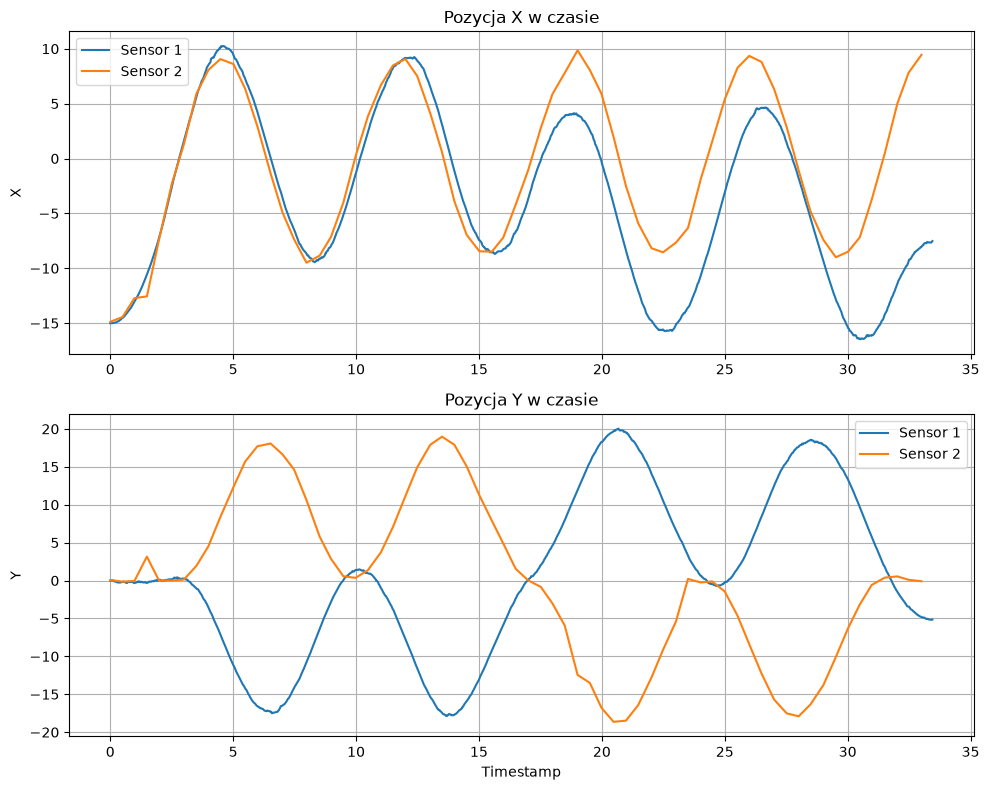

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

ax1.plot(s1['timestamp'], s1['x'], label='Sensor 1')
ax1.plot(s2['timestamp'], s2['x'], label='Sensor 2')
ax1.set_ylabel('X')
ax1.set_title('Pozycja X w czasie')
ax1.grid(True)
ax1.legend()

ax2.plot(s1['timestamp'], s1['y'], label='Sensor 1')
ax2.plot(s2['timestamp'], s2['y'], label='Sensor 2')
ax2.set_xlabel('Timestamp')
ax2.set_ylabel('Y')
ax2.set_title('Pozycja Y w czasie')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

**Wnioski:**
* **Pozycja X:** Na pierwszym wykresie widać że odczyty z obu sensorów układają się w podobny kształt, początkowo są niemal identyczne, ale wraz z upływem czasu niebieski wykres(sensor 1) zaczyna mieć coraz większą rozbieność z wykresem pomarańczowym (sensor 2)
* **Plynność sygnału:** Wykreś niebieski jest bardziej plynny a pomarańczowy ma wiecej skoków i jest bardziej kanciasty co wskazuję na rónice w częstotliwości próbkowania tych czujników (sensor 1 próbkuje w wwiele częściej).
* **Pozycja Y:** Na drugim wykresie, czyli zmiana pozycji Y widać tak samo jak na wykresie 1 ronice w próbkowaniu ale również widać ze odczyty mają przeciwny znak, oznacza to odwróconą orientację osi Y jednego z czujników.


#### Wykres trajektori
Wykres pokzauje z lotu ptaka jak wygladają odczyty z sensorów na płaskiej mapie.

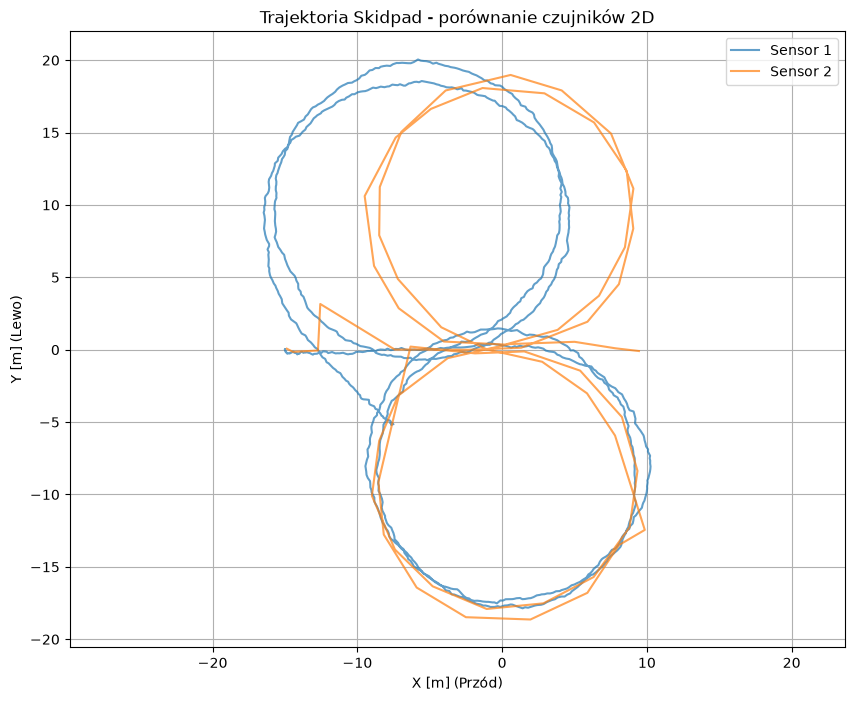

In [ ]:
plt.figure(figsize=(10, 8))

plt.plot(s1['x'], s1['y'], label='Sensor 1', alpha=0.7)
plt.plot(s2['x'], s2['y'], label='Sensor 2', alpha=0.7)
plt.xlabel('X [m] (Przód)')
plt.ylabel('Y [m] (Lewo)')
plt.title('Trajektoria na Skidpad')

plt.axis('equal')
plt.grid(True)
plt.legend()
plt.show()

**Wnioski:**
* Na wykresie widać że na dolnej części odczyty z czujników są podobne 
* W górnej części widać ze niebieski wykres jest przesunięty w lewo i nie z kadym kolejnym przebiegiem koła przesówa się coraz bardziej. Wskazuje to na błąd narastający w czasie, który wystpuje czsto w systemach nawigacji zliczeniowej (IMU, całkowanie sygnału).Mały błąd lokalny ale globalny się stale zwiększa.
* Na wykresie odczytów sensora 2 widać nagłe skoki w niektórych miejscach i bardzje kańciasty wykres (mniejsza częstotliwość próbkowania), ale jego trajektoria poza pojedńczymi wachaniami jest spójna, jest to najprawdopodobniej czujnik GPS który czasami ma szumy jakieś ale ogulnie daje dobry obraz połoenia globalnego

* Podobny błąd występuje m.in. w biegowych czujnikach na buty (foot-podach z układem IMU), które szacują dystans na podstawie ruchu i przyspieszeń. Na krótkim odcinku są bardzo dokładne, ale im dłuższy bieg tym większy staje się błąd.
* W bolidzie Sensor 1 najprawdopodobniej bazuje na pomiarze obrotów kół połączonym z kątem skrętu kierownicy lub na całkowaniu przyspieszeń z czujnika IMU, bład moe się stale zwiększać przez np. uślizgi opon czy jakieś drgania / wyboje.


#### Wykres Częstotliwości
Wykres pokazuje częstotoliość próbkowania sensorów oraz ilość zapisanych przez nie danych w trakcie pomiaru.

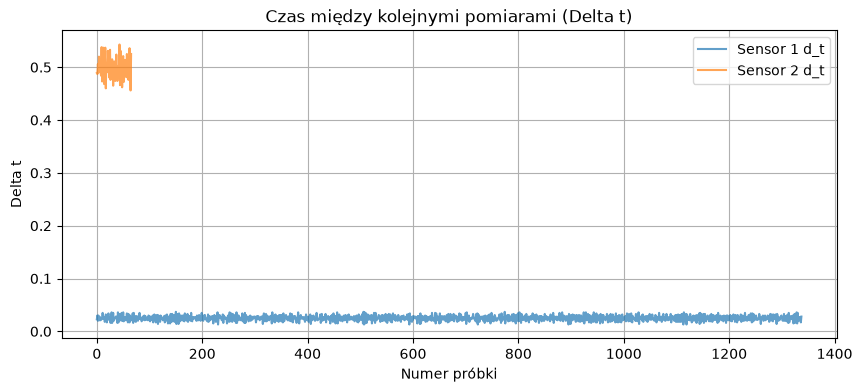

In [17]:
dt_s1 = np.diff(s1['timestamp'])
dt_s2 = np.diff(s2['timestamp'])

plt.figure(figsize=(10, 4))
plt.plot(dt_s1, label='Sensor 1 d_t', alpha=0.7)
plt.plot(dt_s2, label='Sensor 2 d_t', alpha=0.7)
plt.ylabel('Delta t')
plt.xlabel('Numer próbki')
plt.title('Czas między kolejnymi pomiarami (Delta t)')

plt.legend()
plt.grid(True)
plt.show()

**Wnioski:**
* Wykres kroku czasowego potwierdza znaczną różnicę w częstotliwości odświeżania.
* Sensor 1 generuje próbki co ok. 0,025s, a Sensor 2 co ok. 0,5s, więc różnica w częstotliwości próbkowania jest około 20 krotna


#### Wykres pozycji Y w czasie (odwrócony)
Poniewaz wczesniej wykres Y w czasie pokazał ze czujniki zwracaja dane o przeciwnym znaku ten wykres pokazuje jak wyglada przebieg Y w czasie gdy aba czujniki zwracaja ten sam znak.

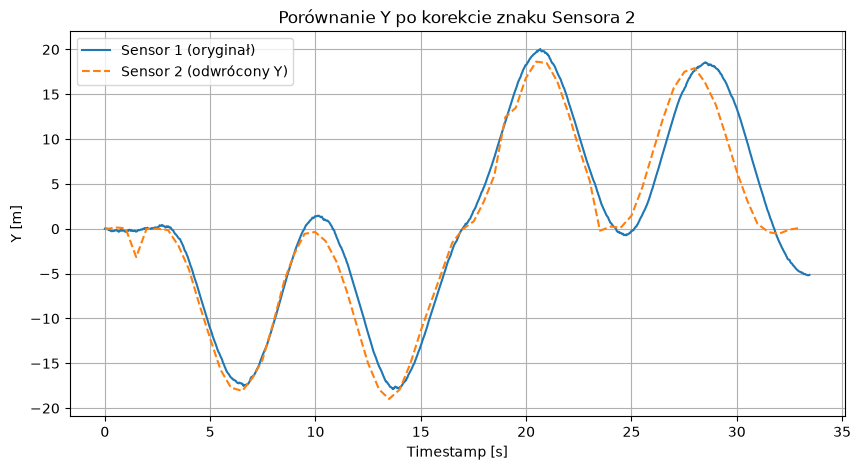

In [ ]:
y_s2_corrected = -s2['y']

plt.figure(figsize=(10, 5))
plt.plot(s1['timestamp'], s1['y'], label='Sensor 1 (oryginał)')
plt.plot(s2['timestamp'], y_s2_corrected, label='Sensor 2 (odwrócony Y)', linestyle='--')
plt.title('Porównanie Y po korekcie znaku Sensora 2')
plt.xlabel('Timestamp [s]')
plt.ylabel('Y [m]')
plt.legend()
plt.grid(True)
plt.show()

**Wniostki:**
* Po odwróceniu znaku osi Y sensora 2, widać że przebiegi obu wykresów są podobne.
* Potwierdza się tu też narastający bład pomiaru sensora 1.
* Widać tez pojedyncze skoki odczytywane z czujnika 2 ktore najprawdopodobniej zawieraja beldy w odczytach spowodowane jakimis zakuceniami.

#### Wykres prędkości auta w czasie
Wykres przedstawia jak zmieniala się predkosć auta w czasie (miedzy dwoma odczytami z czujników ile wynosiła średnia).

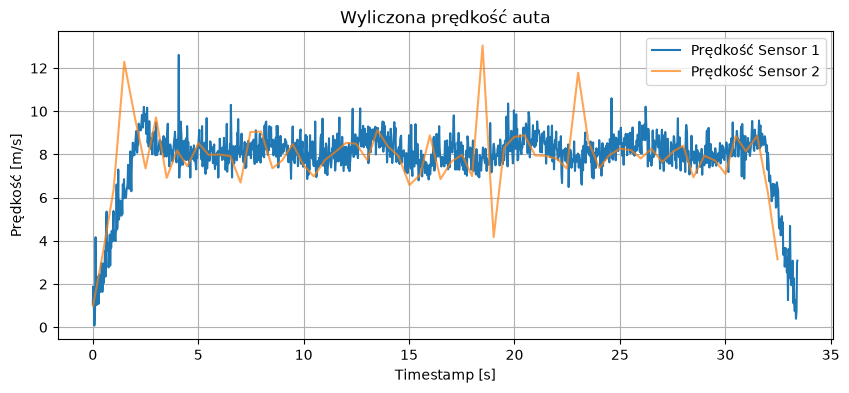

In [ ]:
vx1 = np.diff(s1['x']) / dt_s1
vy1 = np.diff(s1['y']) / dt_s1
v1 = np.sqrt(vx1**2 + vy1**2)

vx2 = np.diff(s2['x']) / dt_s2
vy2 = np.diff(s2['y']) / dt_s2
v2 = np.sqrt(vx2**2 + vy2**2)

plt.figure(figsize=(10, 4))
plt.plot(s1['timestamp'][:-1], v1, label='Prędkość Sensor 1')
plt.plot(s2['timestamp'][:-1], v2, label='Prędkość Sensor 2', alpha=0.7)
plt.ylabel('Prędkość [m/s]')
plt.xlabel('Timestamp [s]')
plt.title('Wyliczona prędkość auta')
plt.legend()
plt.grid(True)
plt.show()

**Wnioski:**
* **Sensor 1:** Pokazuje płynny i realistyczny przebieg predkości pasujący do dynamiki bolidu, co prawda ma niewielkie szumy w niektorych miejscach.
* **Sensor 2:** Zawiera w niektórych miejscach bardzo duże skoki prędkości, które nie są realistyczne dla odczytów z bolidu. Potwierdza to teorie o czujniku GPS który przez rzadkie próbkowanie i szum występujący w odczytach czasami daje nagłe i duże skoki w prędkości 